# HW4: Stock Prediction and Trading Strategy

Xiaofei Yan

Quarterly Ridge predicts gross 90-calendar-day adjusted-price returns. A monthly Top 10 portfolio is evaluated against the S&P 500 total-return index. This notebook explains the experiment and displays outputs generated by the Python scripts. See `README.md` for run instructions.

## 1. Research design

Development: January 2010–December 2015. Chronological validation years: 2012, 2013 and 2014. Buffer: January–March 2016. Final evaluation: April 1, 2016–September 30, 2026. Earlier prices supply feature lookbacks.

Ridge alpha is chosen from `[1, 100, 1000]` by mean validation-fold RMSE and then frozen. Quarterly refits use expanding training samples with `label_end < fit_date`. Preprocessing is refitted on training data only. Financials become usable from filing date plus one calendar day.

Signals formed after a close can enter only at the next session close. Monthly Top 10 selections receive equal dollar budgets totaling at most one third of the preceding NAV, limited by available cash. Budgets include the 5 bps entry fee. Each lot has its own 90-calendar-day maturity; sales also cost 5 bps. Cash earns zero. Positions can remain open at the final date.

For missing maturity quotes, the main reported scenario uses the last accepted pre-maturity price as a hypothetical exit; see Section 7. The strict observed-quote reference is retained separately.

## Common-stock candidate assumption

Use the supplied database for universe screening and model inputs. Sourced operational repairs below supplement execution only. Instrument names, symbol patterns and conservative review exclusions identify probable non-common/uncertain issues. The remaining 3,649 securities are assumed common-stock candidates, not individually verified historical common shares. Entry-quarter membership still applies. See the security/coverage assumptions in `README.md`.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display
base = Path.cwd() if Path('feature_panel.py').is_file() else Path.cwd() / 'Homeworks/HW4/Xiaofei_Yan'
summary_path = base / 'results/security_type_summary.csv'
if summary_path.is_file():
    display(pd.read_csv(summary_path))

,common_stock_candidate,reason,Securities
0,False,explicit_noncommon_name_or_debt_coupon,17
1,False,five_character_subordinate_or_uncertain_issue,100
2,False,partnership_or_royalty_units_not_common_stock,60
3,False,preferred_issue_symbol_review,3
4,False,subordinate_issue_type_unconfirmed,20
5,True,ordinary_share_candidate,3649


In [2]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image

homework_dir = Path.cwd()
if not (homework_dir / 'feature_panel.py').is_file():
    homework_dir = homework_dir / 'Homeworks/HW4/Xiaofei_Yan'
if not (homework_dir / 'feature_panel.py').is_file():
    raise FileNotFoundError('Run from the repository root or personal HW4 directory.')
outputs = homework_dir / 'outputs'
results = homework_dir / 'results'

def result_file(relative):
    submitted = results / Path(relative).name
    return submitted if submitted.is_file() else outputs / relative

def show_csv(relative):
    path = result_file(relative)
    if path.is_file():
        frame = pd.read_csv(path)
        display(frame)
        return frame
    print(f'Not generated yet: {relative}. Run the scripts in README.md.')

## 2. Twenty features

Prices are aligned to the supplied trading calendar without padding gaps. Returns use adjusted close. Within-day range uses consistent raw OHLC; dollar volume is a raw-close-times-volume proxy whose corporate-action basis remains a limitation. Financial ratios use the latest available valid quarterly filing; ratios from fiscal periods older than 550 days are missing. Growth requires a matching fiscal date one year earlier, also disclosed by the current event. Missing growth matches remain missing.

In [3]:
features = [
('Price/volume', '5-day return', 'P[t]/P[t-5] - 1'),
('Price/volume', '21-day momentum', 'P[t]/P[t-21] - 1'),
('Price/volume', 'Long momentum', 'P[t-21]/P[t-252] - 1'),
('Price/volume', '63-day volatility', 'sample std of 63 simple daily returns × sqrt(252)'),
('Price/volume', '252-day drawdown', 'P[t]/trailing 252-price maximum - 1'),
('Price/volume', '63-day relative momentum', 'stock 63-day return minus benchmark return'),
('Price/volume', '252-day beta', 'rolling covariance(stock, market)/market variance'),
('Price/volume', '21-day price range', 'mean((high-low)/close)'),
('Price/volume', 'Volume ratio', '21-session mean volume/252-session mean volume'),
('Price/volume', 'Dollar volume proxy', 'log(21-session mean(raw close × volume))'),
('Fundamental', 'Operating ROA', 'operating income/assets'),
('Fundamental', 'Gross margin', 'gross profit/revenue'),
('Fundamental', 'Revenue growth', 'revenue/prior-year same-fiscal-date revenue - 1'),
('Fundamental', 'Asset growth', 'assets/prior-year same-fiscal-date assets - 1'),
('Fundamental', 'Debt/assets', 'total debt/assets'),
('Fundamental', 'Cash/assets', 'cash/assets'),
('Fundamental', 'FCF/assets', 'free cash flow/assets'),
('Fundamental', 'Accruals/assets', '(net income-operating cash flow)/assets'),
('Fundamental', 'Current ratio', 'current assets/current liabilities'),
('Fundamental', 'Filing age', 'days since filing availability'),
]
display(pd.DataFrame(features, columns=['Group','Feature','Definition']))

,Group,Feature,Definition
0,Price/volume,5-day return,P[t]/P[t-5] - 1
1,Price/volume,21-day momentum,P[t]/P[t-21] - 1
2,Price/volume,Long momentum,P[t-21]/P[t-252] - 1
3,Price/volume,63-day volatility,sample std of 63 simple daily returns × sqrt(252)
4,Price/volume,252-day drawdown,P[t]/trailing 252-price maximum - 1
5,Price/volume,63-day relative momentum,stock 63-day return minus benchmark return
6,Price/volume,252-day beta,"rolling covariance(stock, market)/market variance"
7,Price/volume,21-day price range,mean((high-low)/close)
8,Price/volume,Volume ratio,21-session mean volume/252-session mean volume
9,Price/volume,Dollar volume proxy,log(21-session mean(raw close × volume))


## 3. Data quality and outlier handling

Positive prices alone do not establish reliable returns. Development data included abrupt scale conflicts, including AAM alternating between sub-dollar and five-digit prices. Threshold flags below are conservative review rules, not claims that all large genuine returns are errors. The same causal rules apply in the final period; no security is removed based on its future performance.

In [4]:
notes = (homework_dir / 'README.md').read_text().split('## Price quality policy', 1)[1].split('## Security and coverage assumptions', 1)[0]
display(Markdown(notes))




These conservative rules were chosen after investigating development-period
price records, before evaluating the final test. They are review thresholds,
not evidence that a large genuine return is impossible.

- Preserve the source database. Keep a CSV audit of each flagged quote under
  local `outputs/data_quality/`, with its symbol, date, price, volume and reason.
- Quarantine nonpositive/nonfinite adjusted prices, following the course policy.
- Quarantine a zero-volume quote when its adjusted price is at least 100 times
  or at most 1/100 of the latest preceding positive-volume adjusted price.
  This flags the inconsistent zero-volume price regime seen in AAM, without
  assuming which corporate action or vendor issue caused it.
- After that step, flag observed-price changes of at least 10 times or at most
  1/10 as unresolved scale transitions. These are not automatically rescaled
  or declared erroneous; real events can also trigger this conservative flag.
- Mark new-entry/training signals ineligible when the trailing 253 market
  sessions include a quality flag. That prevents the 252-return features from
  crossing the unresolved event, using only information known by the signal.
- Censor a training target if its entry-to-exit interval includes a flagged
  quote. Preserve the original target as `target_before_quality`. Future label
  availability/quality is never used to decide whether to buy at a past signal.
- Do not interpolate, fabricate split factors, remove an entire stock using
  its future history, or clip validation targets to make reported errors smaller.

Lecture 8's training-fitted 1st/99th-percentile feature clipping remains in the
Ridge pipeline. It is distinct from source-price review and label censoring.
Financials still follow the lecture's filing-date-plus-one-day availability
rule and stale-data treatment. Restated vendor snapshots and unverified price
adjustments remain limitations. Flagged quotes in an existing holding require
the backtest's missing/unresolved-price policy; an entry screen alone does not
make held-position valuation reliable.




## 4. Development validation

All stocks on a date stay in the same fold. Training outcomes must finish before the first validation signal. Quantile clipping, median imputation with missing indicators, and scaling are learned separately within training folds. Validation targets are not clipped. The chosen alpha is not retuned using final-period performance.

In [5]:
validation_path = result_file('development/validation_results.csv')
if validation_path.is_file():
    validation = pd.read_csv(validation_path)
    display(validation[['param_model__alpha', 'mean_validation_rmse', 'rank_test_score']].rename(columns={'param_model__alpha': 'Alpha', 'mean_validation_rmse': 'Mean validation RMSE', 'rank_test_score': 'Rank'}))
else:
    print('Run model_selection.py first.')

,Alpha,Mean validation RMSE,Rank
0,1,0.199407,3
1,100,0.199405,2
2,1000,0.199389,1


## 5. Accounting and timing evidence

Hand-verifiable synthetic cases cover fees, daily cash reconciliation, NAV, realized PnL, next-session entries, weekend maturity, overlapping lots, open positions, missing entries/exits, stale marks and unresolved price transitions. These cases check accounting; they do not prove that the supplied real-world prices are correct.

In [6]:
check_path = result_file('accounting_checks.json')
if check_path.is_file():
    checks = json.loads(check_path.read_text())
    display(pd.Series({k:v for k,v in checks.items() if k != 'cases'}))
    display(pd.DataFrame({'Passed case': checks['cases']}))
else:
    print('Run python accounting_checks.py first.')

status                                    passed
flat_price_expected_fee_per_side      166.583375
flat_price_expected_final_value     999666.83325
flat_price_observed_final_value     999666.83325
dtype: object

,Passed case
0,flat-price round-trip fees
1,daily cash reconciliation
2,NAV identity
3,realized PnL
4,signal before entry
5,weekend maturity
6,overlapping lots and open-position end NAV
7,missing entry
8,no orders
9,missing maturity quote waits for observed fill


## 6. Quarterly fitting audit

A fit after the last session before each quarter supplies the three monthly signal dates in that quarter. Scores include eligible stocks even when future labels are unavailable. Fit dates and last completed training outcomes are saved for inspection.

In [7]:
audit = show_csv('final/predictions/fit_audit.csv')
if audit is not None:
    assert (pd.to_datetime(audit.last_label_end) < pd.to_datetime(audit.fit_date)).all()

,fit_date,training_rows,last_training_signal,last_label_end,scored_rows
0,2016-03-31,2912177,2015-12-30,2016-03-30,5822
1,2016-06-30,3030342,2016-03-30,2016-06-29,5802
2,2016-09-30,3156242,2016-06-30,2016-09-29,5814
3,2016-12-30,3278193,2016-09-29,2016-12-29,5804
4,2017-03-31,3400371,2016-12-29,2017-03-30,5800
5,2017-06-30,3520194,2017-03-30,2017-06-29,5790
6,2017-09-29,3641842,2017-06-29,2017-09-28,5817
7,2017-12-29,3763344,2017-09-28,2017-12-28,5795
8,2018-03-29,3883478,2017-12-27,2018-03-28,5817
9,2018-06-29,4003425,2018-03-28,2018-06-27,5810


## 7. Full-period scenario and strict reference

The main scenario reaches 2026-09-30 using the explicitly requested **last-before-maturity** assumption. Missing quotes are carried for daily valuation. If a current quote is unavailable on the first market session on/after a lot's 90-day maturity, the lot is hypothetically closed at its last accepted pre-maturity quote, with 5 bps exit cost. Cash is booked on the assumed exit date, not backdated to the old quote date. These entries are labeled `ASSUMED_STALE_EXIT`; they are not observed executable fills. This scenario relaxes the assignment's observed-fill requirement and must not be represented as strict completion of that requirement.

Three such exits occur: PEGY and WOLF on 2024-12-02, and ASGN on 2026-07-30. The assumptions affect both reported NAV and later purchase budgets. Genuine BID/DISH corporate-action treatment and the BODY/BODI execution supplement remain in place. Frozen model parameters and forecast rankings are unchanged; no stock is removed for future missing coverage.

The strict reference stops on 2024-10-22 at WOLF, with completed history through 2024-10-21. Its status, partial performance and unresolved lots are retained in `results/strict_reference/`. Its shorter-period performance is not directly comparable with the full-period scenario. See README.md for sources and limitations.

requested_start                                                                   2016-04-01
requested_end                                                                     2026-09-30
retrospective_coverage_exclusions                                                      False
missing_price_policy                                                    last_before_maturity
evaluation_type                                             hypothetical stale-exit scenario
data_source                                course database plus sourced corporate actions...
status                                                             complete_with_assumptions
last_evaluated_date                                                               2026-09-30
assumed_exit_count                                                                         3
assumed_exit_symbols                                                      [ASGN, PEGY, WOLF]
maximum_assumed_exit_quote_age_sessions                               

**Full requested window reached using hypothetical stale-price maturity exits; these are not observed market fills.**

portfolio,quarterly Ridge,S&P 500 total return
final_value,"$638,351.87","$4,402,746.78"
total_return,-36.16%,340.27%
CAGR,-4.19%,15.17%
max_drawdown,-85.95%,-33.79%
annualized_volatility,39.41%,17.82%
Sharpe,0.038,0.773


Strategy minus benchmark total return over evaluated coverage: -376.44 percentage points.


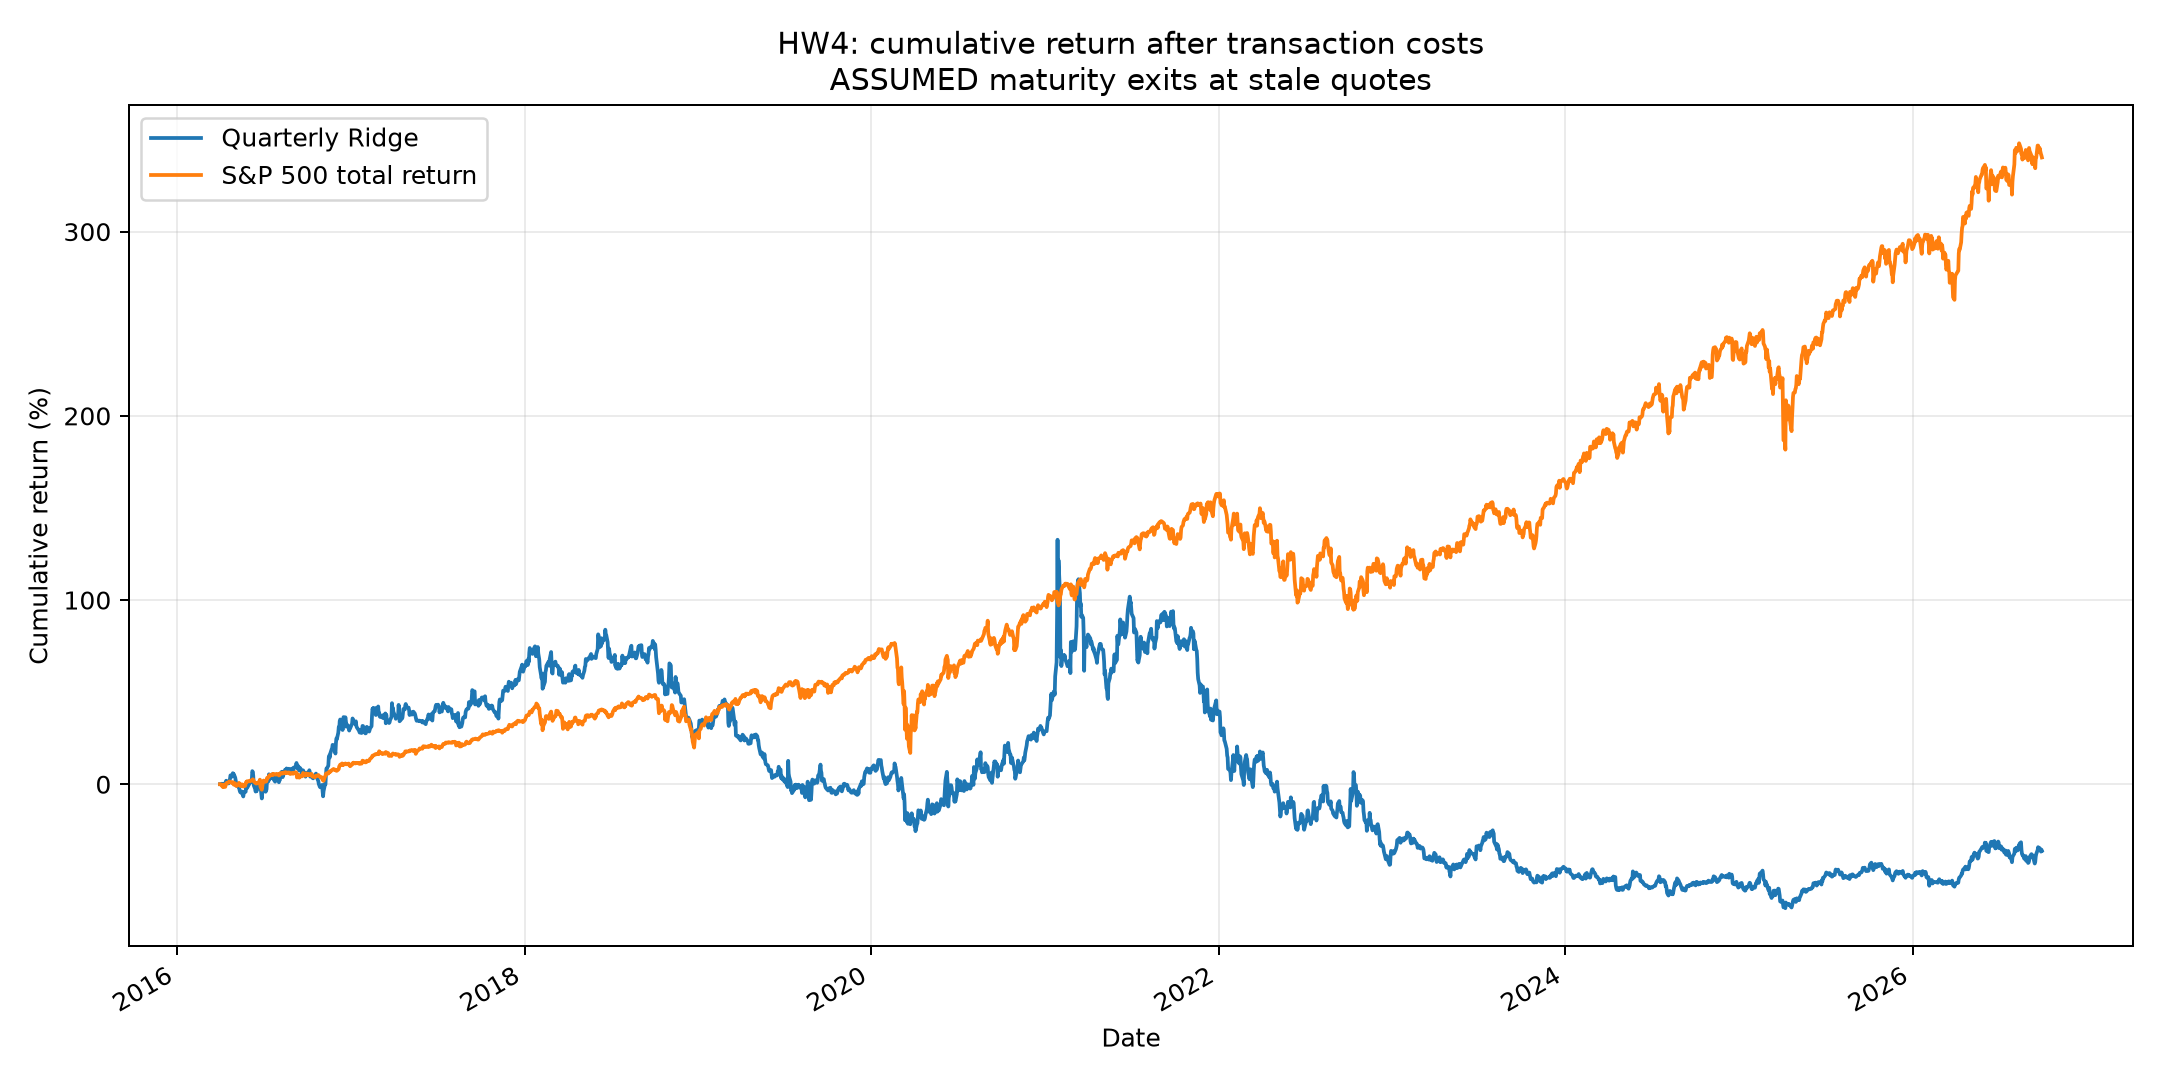

In [8]:
status_path = result_file('final/run_status.json')
if status_path.is_file():
    run_status = json.loads(status_path.read_text())
    display(pd.Series(run_status))
    if run_status['status'] == 'complete_with_assumptions':
        display(Markdown('**Full requested window reached using hypothetical stale-price maturity exits; these are not observed market fills.**'))
    elif run_status['status'] != 'complete':
        display(Markdown('**PARTIAL evaluation only; the requested 2026-09-30 end has not been reached.**'))
comparison_path = result_file('final/performance.csv')
if comparison_path.is_file():
    comparison = pd.read_csv(comparison_path, index_col=0)
    order = ['final_value','total_return','CAGR','max_drawdown','annualized_volatility','Sharpe']
    formatted = comparison[order].T.astype(object)
    for metric in order:
        fmt = '${:,.2f}' if metric == 'final_value' else ('{:.3f}' if metric == 'Sharpe' else '{:.2%}')
        formatted.loc[metric] = comparison[metric].map(lambda v: fmt.format(v) if pd.notna(v) else 'N/A')
    display(formatted)
    gap = comparison.iloc[0].total_return - comparison.iloc[1].total_return
    print(f'Strategy minus benchmark total return over evaluated coverage: {gap * 100:+.2f} percentage points.')
chart = result_file('final/cumulative_returns.png')
if chart.is_file(): display(Image(filename=str(chart)))

### Account and PnL at the last evaluated date

The account fields follow Lecture 8: cash plus marked holdings equals NAV; realized plus unrealized PnL equals total PnL. Unrealized PnL includes the remaining lots’ entry fees. Fees are already included in PnL, so they are not subtracted twice.

In [9]:
account_path = result_file('final/account_summary.csv')
if account_path.is_file():
    account = pd.read_csv(account_path, index_col='metric')['value']
    display(account.rename('Value ($)').to_frame().map(lambda value: f'{value:,.2f}'))
    assert abs(account['cash'] + account['holdings_value'] - account['nav']) < 1e-5
    assert abs(account['realized_pnl'] + account['unrealized_pnl'] - account['total_pnl']) < 1e-5
else:
    print('Generate the account snapshot with run_strategy.py.')

,Value ($)
metric,
cash,"215,107.12"
holdings_value,"423,244.76"
nav,"638,351.87"
realized_pnl,"-386,702.99"
unrealized_pnl,"25,054.86"
total_pnl,"-361,648.13"
total_fees,"33,539.91"


### Portfolio diagnostics (Lecture 8)

These diagnostics exclude the initial-capital row from average cash and mean NAV, as in Lecture 8. Gross traded over average NAV counts both purchase and sale notionals; it is not annualized or one-way turnover.

In [10]:
diagnostic_path = result_file('final/portfolio_diagnostics.csv')
if diagnostic_path.is_file():
    portfolio_diagnostics = pd.read_csv(diagnostic_path, index_col='metric')['value']
    display(portfolio_diagnostics)
else:
    print('Generate portfolio diagnostics with run_strategy.py.')

metric
average_cash_fraction                0.218068
fees                             33539.914660
gross_traded_over_average_nav       66.342073
open_lots_at_end                    20.000000
stale_marks                         93.000000
Name: value, dtype: float64

### Cash fraction and drawdown

Following Lecture 8, cash fraction is `cash / NAV`. Drawdown is `NAV / NAV.cummax() - 1`, calculated separately for the strategy and benchmark. It can recover to zero when a new peak is reached. These charts use the same saved daily account history as the cumulative-return plot.

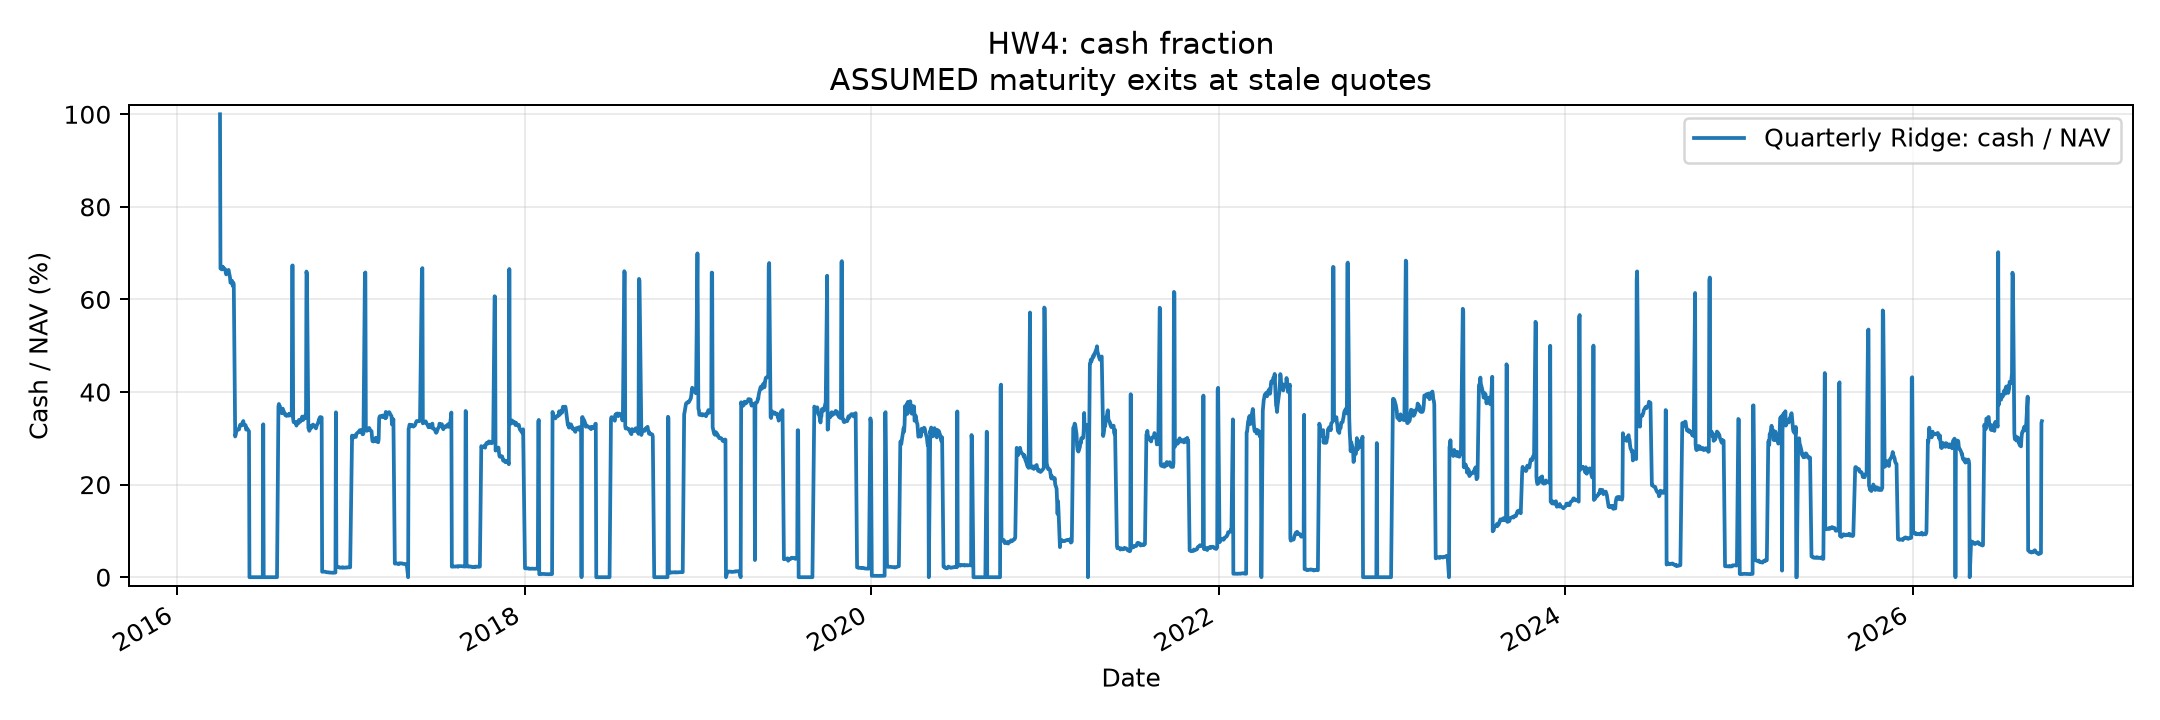

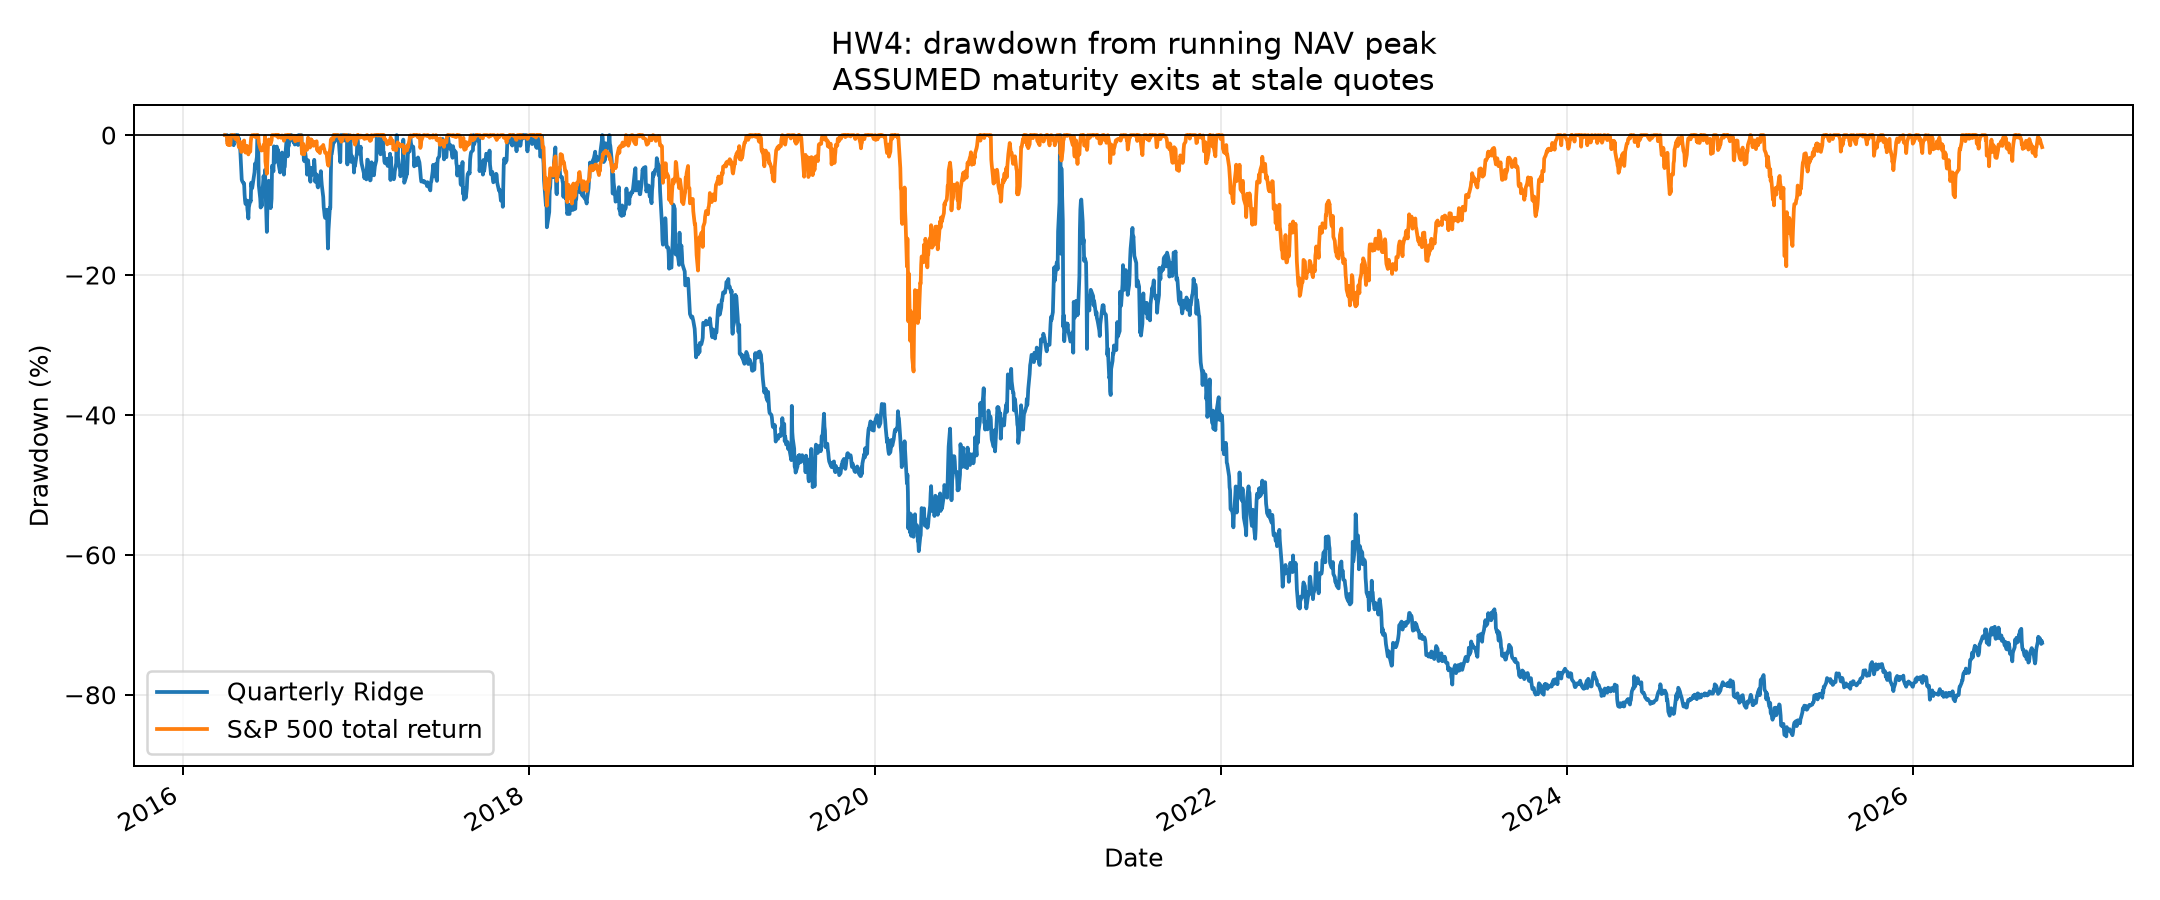

In [11]:
for filename in ['cash_fraction.png', 'drawdown.png']:
    path = result_file('final/' + filename)
    if path.is_file():
        display(Image(filename=str(path)))
    else:
        print(f'Generate {filename} with run_strategy.py.')

In [12]:
history_path = result_file('final/daily_nav.csv')
trades_path = result_file('final/trades.csv')
if history_path.is_file() and trades_path.is_file():
    history = pd.read_csv(history_path)
    trades = pd.read_csv(trades_path)
    display(pd.Series({
        'Average cash share of NAV': (history.cash / history.nav).iloc[1:].mean(),
        'Total transaction fees ($)': trades.fee.sum(),
        'Purchases': trades.side.eq('BUY').sum(),
        'Market sales': trades.side.eq('SELL').sum(),
        'Assumed stale-price exits': trades.side.eq('ASSUMED_STALE_EXIT').sum(),
        'Cash mergers': trades.side.eq('CASH_MERGER').sum(),
        'Open lots at end': history.open_lots.iloc[-1],
    }))
    print('Most frequently purchased securities:')
    display(trades.loc[trades.side.eq('BUY'), 'symbol'].value_counts().head(10))
assumed_path = result_file('final/assumed_exits.csv')
if assumed_path.is_file():
    assumed_exits = pd.read_csv(assumed_path)
    print('Hypothetical maturity exits: prices from earlier dates, not observed execution-day fills')
    display(assumed_exits[['symbol', 'entry_date', 'due_date', 'date', 'price_date', 'price', 'stale_sessions', 'cash_change']])
strict_path = results / 'strict_reference/run_status.json'
if strict_path.is_file():
    print('Strict reference status (shorter interval):')
    display(pd.Series(json.loads(strict_path.read_text())))


Average cash share of NAV         0.218068
Total transaction fees ($)    33539.914660
Purchases                      1220.000000
Market sales                   1196.000000
Assumed stale-price exits         3.000000
Cash mergers                      1.000000
Open lots at end                 20.000000
dtype: float64

Most frequently purchased securities:


symbol
BESS    44
BNED    19
PZN     18
CRC     16
WINA    15
OPEN    15
TDW     14
UPST    13
PEGY    12
AMC     12
Name: count, dtype: int64

Hypothetical maturity exits: prices from earlier dates, not observed execution-day fills


,symbol,entry_date,due_date,date,price_date,price,stale_sessions,cash_change
0,PEGY,2024-09-03,2024-12-02,2024-12-02,2024-11-19,3.400,8.0,102.282519
1,WOLF,2024-09-03,2024-12-02,2024-12-02,2024-10-14,11.235,34.0,1457.299040
2,ASGN,2026-05-01,2026-07-30,2026-07-30,2026-05-22,19.500,46.0,12582.164176


Strict reference status (shorter interval):


requested_start                                                             2016-04-01
requested_end                                                               2026-09-30
retrospective_coverage_exclusions                                                False
data_source                          course database plus sourced corporate actions...
status                                                                      incomplete
failed_date                                                                 2024-10-22
reason                                Held quote gap exceeds limit: WOLF on 2024-10-22
last_evaluated_date                                                         2024-10-21
dtype: object

## 8. Limitations and attribution

Financial records are vendor snapshots rather than original filing vintages. Security mappings, price adjustments and delisting proceeds are not fully verified. The quality screen is conservative and can exclude genuine events; it cannot certify all remaining prices. Quarter-specific membership reduces one source of future selection bias but does not remove all source coverage bias. The 90-day prediction targets overlap and cannot be compounded as portfolio returns.

Adapted course code: `Lectures/modeling/course_data.py` (price features, financial events, membership alignment, labels, chronological folds and preprocessing) and the workflow in `Lectures/Lecture 8/2_research_workflow.ipynb`. Accounting and scheduling concepts reference `1_backtesting.ipynb`; `portfolio_backtest.py` implements its own bookkeeping without importing the course backtester. Codex assisted with research planning, code implementation and diagnostic checks. Further research could verify flagged corporate actions and compare a nonlinear model using development data only.

Carrying stale prices suppresses measured variation during gaps. Hypothetical cash recovery may overstate realizable proceeds and changes later allocations. The full-period scenario is conditional on these assumptions, not a guaranteed performance bound.

## 9. Findings and further work

The quarterly Ridge strategy underperforms the benchmark in the full-period **assumed-exit scenario**. Results include three hypothetical exits at pre-maturity stale quotes, explicitly recorded in results/assumed_exits.csv with their original quote dates. WOLF exits hypothetically on 2024-12-02 at its 2024-10-14 quote, rather than carrying old shares into a 2025 post-reorganization price. The strict reference remains partial, with unresolved WOLF still retained in results/strict_reference/open_positions.csv. The full requested window has been simulated under assumptions; observed-fills-only evaluation remains incomplete.

BID's compulsory cash consideration, DISH's conversion to EchoStar (database alias ECHO, official ticker SATS), and the BODY/BODI execution-quote supplement are documented operational repairs investigated after failures. They are not model retuning. Neither supplemental execution quotes nor the stale-exit policy change features, training labels or forecast rankings. Source mappings and vendor differences remain limitations.

Random Forest was abandoned for runtime. The earlier future-coverage exclusion experiment was withdrawn. The next useful work is to obtain genuine missing histories, verify security identity and corporate actions, and compare the strict and assumed-exit policies over the same full interval. Source restatements, historical security-type assumptions and execution liquidity also remain limitations.